<a href="https://colab.research.google.com/github/AlexBecerril/miaad-sem1/blob/main/Pr%C3%A1cticaRegresionDatosCategoricos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**Regresión lineal con datos categóricos: Costos, Localidades y Salarios**

**Nombre:** Edgar Alejandro Becerril Caballero  
**Matricula:** 275333

##**Objetivos de la Práctica:**
**Al finalizar esta práctica, los estudiantes serán capaces de:**

- Codificar variables categóricas usando one-hot encoding con K-1 para problemas de regresión
- Realizar AED
- Construir un modelo de regresión con variables dummy
- Interpretar los resultados de los coeficientes
- Analizar los resultados de los errores residuales
- Calcular el desempeño del modelo de regresión.

Problema: Se podría argumentar que el salario está relacionado con el costo de la educación. Por lo tanto, para analizar este argumentos veremos qué sucede cuando usamos las variables independientes cost y location.

# 1. Carga de datos

Carga el conjunto de datos college.csv, que está en campus virtual, en un dataframe. Elige de este conjunto las columnas salary (variable dependiente), cost(variable independiente - numérica) y location (variable independiente categórica).

Realiza lo siguiente:

*   Convierte si es necesario la variable location a tipo de dato categórico
*   Usa la instrucción describe() en las variables salary y cost
* Cuenta la cantidad de datos que hay por categoría en location
* Convierte la variable location usando one-hot encoding



In [1]:
# Importar librerías
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [2]:
# Montar Google Drive para acceder al archivo del conjunto de datos.
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# Cargar el conjunto de datos college.csv desde Google Drive
# y mostrar las primeras observaciones para revisar su estructura.
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/datasets/college.csv')
df.head()

,id,name,salary,cost,public,location
0,1,Massachusetts Institute of Technology (MIT),119000,189300,Private,NE
1,2,Harvard University,121000,189600,Private,NE
2,3,Dartmouth College,123000,188400,Private,NE
3,4,Princeton University,123000,188700,Private,NE
4,5,Yale University,110000,194200,Private,NE


In [4]:
# Consultar la información general del DataFrame para revisar
# las columnas, sus tipos de datos y la presencia de valores nulos.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 85 entries, 0 to 84
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   id        85 non-null     int64 
 1   name      85 non-null     object
 2   salary    85 non-null     int64 
 3   cost      85 non-null     int64 
 4   public    85 non-null     object
 5   location  85 non-null     object
dtypes: int64(3), object(3)
memory usage: 4.1+ KB


In [5]:
# Hacer una copia del conjunto de datos para su manipulación con las columnas salary, cost y location unicamente.
df_copy = df[['salary','cost','location']].copy()
df_copy.head()

,salary,cost,location
0,119000,189300,NE
1,121000,189600,NE
2,123000,188400,NE
3,123000,188700,NE
4,110000,194200,NE


In [6]:
# Convertir location a tipo categórico para indicar que sus valores
# representan categorías y no cantidades numéricas.
df_copy['location'] = df_copy['location'].astype('category')
df_copy.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 85 entries, 0 to 84
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   salary    85 non-null     int64   
 1   cost      85 non-null     int64   
 2   location  85 non-null     category
dtypes: category(1), int64(2)
memory usage: 1.7 KB


In [7]:
# Obtener estadísticas descriptivas de salary y cost.
df_copy.describe()

,salary,cost
count,85.000000,85.000000
mean,95898.823529,142434.470588
std,11937.121912,53913.064578
min,74900.000000,18260.000000
25%,87100.000000,84670.000000
50%,93200.000000,169200.000000
75%,105000.000000,188700.000000
max,123000.000000,227300.000000


In [8]:
# Se agrupan los datos por location y se calculan las estadísticas
# descriptivas de cost y salary para cada categoría.
df_copy.groupby('location', observed=False)[['cost','salary']].describe()

cost                                                            \
         count           mean           std      min       25%       50%   
location                                                                   
MW        19.0  143859.473684  52897.181029  69990.0   89300.0  166700.0   
NE        25.0  163034.800000  48754.389043  18260.0  137100.0  187700.0   
S         20.0  146171.500000  54620.280047  70150.0   87222.5  173950.0   
W         21.0  113061.904762  50504.019703  56970.0   79310.0   86820.0   

                             salary                                        \
               75%       max  count           mean           std      min   
location                                                                    
MW        193250.0  214400.0   19.0   93694.736842   6995.830003  83000.0   
NE        189600.0  227300.0   25.0  106888.000000  10482.776350  83900.0   
S         188225.0  226600.0   20.0   96635.000000   7943.966595  84300.0   
W         168500.0  213000.0   21.0   84109.523810   7782.474206  74900.0   

                                                  
               25%       50%       75%       max  
location                                          
MW         90100.0   91900.0   96900.0  112000.0  
NE        104000.0  107000.0  111000.0  123000.0  
S          91300.0   94300.0  101750.0  117000.0  
W          80100.0   82100.0   85900.0  113000.0

## Observaciones

Al analizar las medianas de las variables cost y salary por ubicación, se observa que el costo de la educación es superior al salario en todas las regiones. La diferencia es más pronunciada en el noreste (NE), con 80,700, y en el sur (S), con 79,650, mientras que en el oeste (W) se reduce a 4,720. Esto evidencia diferencias regionales en la relación entre el costo educativo y los salarios.

In [9]:
# Contar cuántos registros pertenecen a cada categoría de location.
df_copy['location'].value_counts()

,count
location,
NE,25
W,21
S,20
MW,19


In [10]:
# Aplicar one-hot encoding para convertir las categorías de location en columnas binarias.
df_encoded = pd.get_dummies(df_copy, columns=['location'], drop_first=True)
df_encoded.head()

,salary,cost,location_NE,location_S,location_W
0,119000,189300,True,False,False
1,121000,189600,True,False,False
2,123000,188400,True,False,False
3,123000,188700,True,False,False
4,110000,194200,True,False,False


# 2. Análisis Exploratorio de los Datos

Realiza un análisis exploratorio de los datos y discute lo que observas en cada gráfica.


*   Crea un histograma de la columna salary. Discute lo que observas
* Crea un diagrama de dispersión de salary vs cost, considerando lo siguiente: para cada punto elegirás un color que represente la localidad en la que está el salario y el costo de la educación. Por lo tanto el diagrama de dispersión debería tener puntos en 4 colores distintos. Discute lo que observas
* Emplea un boxplot para saber si hay diferencias en los costos según la ubicación, es decir, con boxplot deberás analizar la distribución de cost por localidad. Discute lo que observas




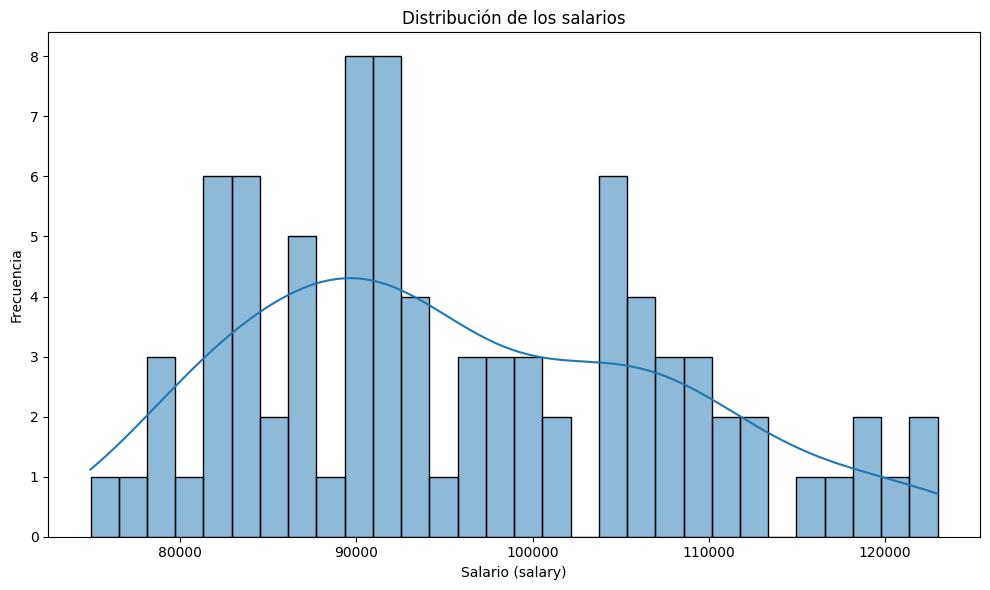

In [11]:
# Se crea un histograma para visualizar la distribución de los salarios.
plt.figure(figsize=(10, 6))

sns.histplot(data=df_copy, x='salary', bins=30, kde=True)

plt.title('Distribución de los salarios')
plt.xlabel('Salario (salary)')
plt.ylabel('Frecuencia')
plt.tight_layout()
plt.show()

## Observaciones

En el histograma se observa que la distribución de los salarios presenta una asimetría positiva o sesgo hacia la derecha. La mayor concentración de observaciones se encuentra entre 85,000 y 95,000, mientras que existe una cola más extendida hacia los salarios elevados.

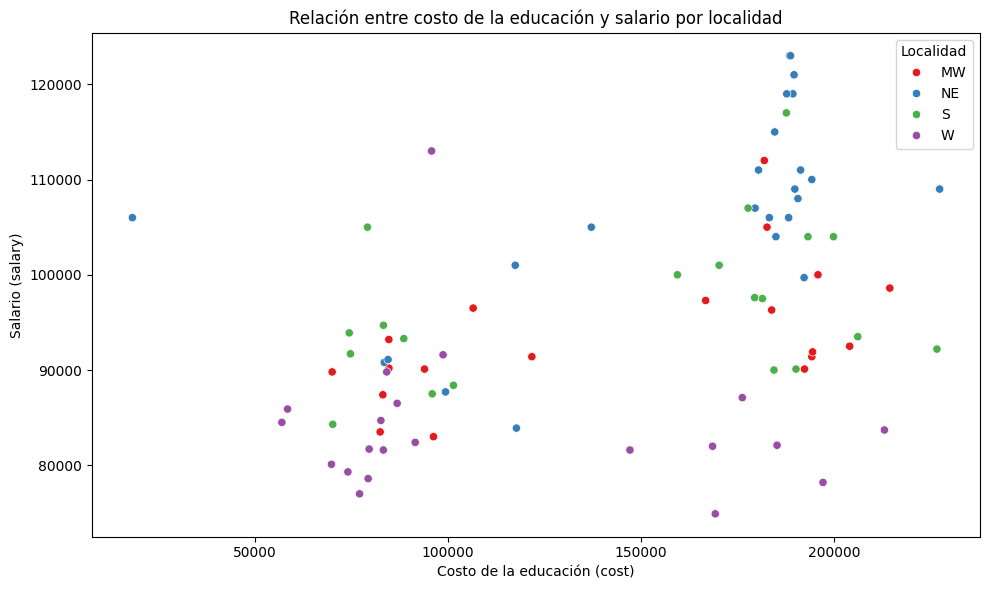

In [12]:
# Se crea un diagrama de dispersión para analizar la relación entre
# el costo de la educación y el salario, diferenciando cada localidad
# mediante un color.
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_copy,
    x='cost',
    y='salary',
    hue='location',
    palette='Set1'
)

plt.title('Relación entre costo de la educación y salario por localidad')
plt.xlabel('Costo de la educación (cost)')
plt.ylabel('Salario (salary)')
plt.legend(title='Localidad')
plt.tight_layout()
plt.show()

## Observaciones

En el diagrama de dispersión se observa una amplia dispersión de los datos, aunque existen algunos patrones interesantes según la localidad. En la región W, la mayoría de los salarios se encuentra por debajo de los 90,000, mientras que en NE se observa una mayor concentración de salarios elevados, particularmente por encima de los 100,000. Por otra parte, los datos muestran agrupaciones en distintos niveles de costo educativo, aproximadamente entre 70,000 y 100,000, y nuevamente entre 170,000 y 200,000. Sin embargo, dentro de estos grupos existe variabilidad en los salarios, por lo que no se aprecia una relación lineal claramente definida entre el costo de la educación y el salario para todas las localidades.

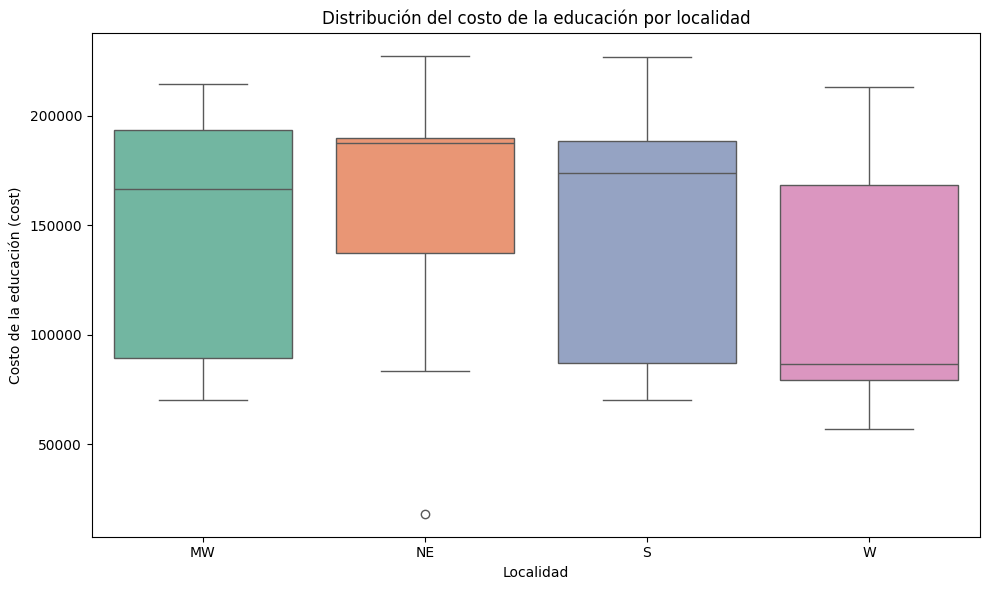

In [13]:
# Se utiliza un boxplot para comparar la distribución de los costos
# entre las cuatro localidades, identificando medianas, dispersión
# y posibles valores atípicos.
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df_copy,
    x='location',
    y='cost',
    hue='location',
    palette='Set2',
    legend=False
)

plt.title('Distribución del costo de la educación por localidad')
plt.xlabel('Localidad')
plt.ylabel('Costo de la educación (cost)')
plt.tight_layout()
plt.show()

In [14]:
# Se agrupan los datos por location y se calculan las estadísticas
# descriptivas de cost para cada categoría.
df_copy.groupby('location', observed=False)[['cost']].describe()

cost                                                            \
         count           mean           std      min       25%       50%   
location                                                                   
MW        19.0  143859.473684  52897.181029  69990.0   89300.0  166700.0   
NE        25.0  163034.800000  48754.389043  18260.0  137100.0  187700.0   
S         20.0  146171.500000  54620.280047  70150.0   87222.5  173950.0   
W         21.0  113061.904762  50504.019703  56970.0   79310.0   86820.0   

                              
               75%       max  
location                      
MW        193250.0  214400.0  
NE        189600.0  227300.0  
S         188225.0  226600.0  
W         168500.0  213000.0

## Observaciones

En el boxplot se observan diferencias importantes en la distribución de los costos educativos según la localidad.

En MW, el 50% central de los datos se encuentra entre 89,300 y 193,250, con una mediana de 166,700. Como la mediana está más cerca del tercer cuartil que del primero, se observa una mayor dispersión en la mitad inferior de la caja, lo que indica una asimetría negativa.

En NE, el 50% central de los datos se encuentra entre 137,100 y 189,600, con una mediana de 187,700. La mediana está muy cerca del cuartil superior y se observa un valor atípico inferior cercano a 18,000, lo que sugiere una distribución con una cola hacia los costos más bajos.

En S, el 50% central de los datos se encuentra entre 87,222.5 y 188,225, con una mediana de 173,950. Al igual que en MW, la mediana está más cerca del cuartil superior, lo que indica también una asimetría negativa.

Por último, W presenta una mediana de 86,820 y un rango intercuartílico entre 79,310 y 168,500. La mediana está más cerca del primer cuartil, lo que indica una asimetría positiva, con mayor dispersión hacia los costos elevados.

# 3. Construcción del modelo de regresión

- Construye el modelo de regresión usando los datos de salario, costo y location. Recuerda que esta última debe ser en su versión codificada con one-hot encoding.
- Imprime los coeficientes e interpreta qué significan cuando se sustituyen valores en costo, y location (versión codificada). Si no recuerdas cómo se hace esta interpretación consulta los videos.


In [15]:
# Definir la variable dependiente (salario) y las variables independientes
X = df_encoded[['cost'] + [col for col in df_encoded.columns if col.startswith('location_')]]
y = df_encoded['salary']

# Crear y entrenar el modelo
modelo = LinearRegression()
modelo.fit(X, y)

# Imprimir el intercepto y los coeficientes
print(f'Intercepto: {modelo.intercept_:.4f}')

for variable, coeficiente in zip(X.columns, modelo.coef_):
    print(f'{variable}: {coeficiente:.4f}')

Intercepto: 84988.7162
cost: 0.0605
location_NE: 12032.8197
location_S: 2800.3450
location_W: -7721.4201


## Observaciones

El intercepto es de 84,988.72 y representa el salario estimado para la localidad de referencia (MW) cuando el costo educativo es cero.

El coeficiente de cost es de 0.0605, lo que significa que por cada unidad adicional en el costo educativo, el salario estimado aumenta 0.0605 unidades, manteniendo constante la ubicación.

En cuanto a las diferencias por localidad, NE presenta un coeficiente positivo de 12,032.82, lo que indica que sus salarios estimados son mayores que los de MW para un mismo costo educativo. S también presenta una diferencia positiva, aunque menor, de 2,800.35. Por el contrario, W tiene un coeficiente negativo de -7,721.42, lo que indica que sus salarios estimados son menores que los de MW cuando se mantiene constante el costo.

En general, los resultados sugieren que tanto el costo educativo como la ubicación contribuyen a explicar las diferencias salariales observadas.

# 4. Análisis de Residuos

- Construyen una visualización de predicciones (salario estimado) vs valores reales (salario real).
- Crea una gráfica de los errores residuales. Discute lo que observas

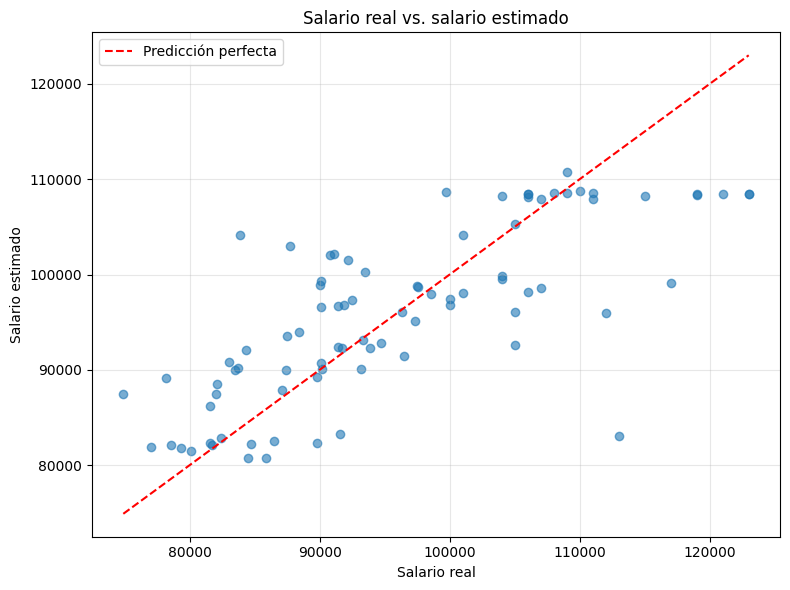

In [16]:
# Generar las predicciones del modelo
y_pred = modelo.predict(X)

# Graficar los valores reales contra los estimados
plt.figure(figsize=(8, 6))
plt.scatter(y, y_pred, alpha=0.6)

# Agregar una línea de referencia para predicciones perfectas
limite_min = min(y.min(), y_pred.min())
limite_max = max(y.max(), y_pred.max())
plt.plot([limite_min, limite_max],
         [limite_min, limite_max],
         color='red', linestyle='--', label='Predicción perfecta')

plt.title('Salario real vs. salario estimado')
plt.xlabel('Salario real')
plt.ylabel('Salario estimado')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Observaciones

El modelo captura parte de la tendencia general, pero presenta limitaciones para estimar los salarios más altos y más bajos. Esto podría deberse a que el costo educativo y la ubicación no explican por completo las diferencias salariales.

# 5. Evalúa el modelo

- Calcula el MSE del modelo construido. Recuerda que usas el propio conjunto de datos (No hablamos nada de entrenamiento y test).
- Calcula el R² Score

Discute estos resultados obtenidos.

In [17]:
# Calcular el error cuadrático medio (MSE)
mse = mean_squared_error(y, y_pred)

# Calcular el coeficiente de determinación (R²)
r2 = r2_score(y, y_pred)

# Imprimir los resultados
print(f'MSE: {mse:.4f}')
print(f'R² Score: {r2:.4f}')

MSE: 60480269.1466
R² Score: 0.5705


## Observaciones

El modelo de regresión lineal obtuvo un MSE de 60,480,269.15 y un R² de 0.5705. Esto indica que el modelo explica aproximadamente el 57.05% de la variabilidad de los salarios a partir del costo educativo y la ubicación geográfica.

Aunque las variables permiten identificar parte de las diferencias salariales, el modelo no explica el 42.95% restante, lo que sugiere que existen otros factores que podrían influir en los salarios.

Estos resultados son consistentes con la dispersión observada en la gráfica de salarios reales frente a salarios estimados, donde algunas predicciones se alejan considerablemente de los valores reales.

# 6. Realiza un análisis de varianza con stastmodel

Consulta esto aquí https://www.statsmodels.org/dev/examples/notebooks/generated/variance_components.html

In [18]:
# Importar la librería para construir modelos estadísticos
import statsmodels.api as sm
from statsmodels.formula.api import ols

# Construir el modelo de regresión incluyendo costo y ubicación
modelo_anova = ols(
    'salary ~ cost + C(location)',
    data=df_copy
).fit()

# Realizar el análisis de varianza
anova_resultado = sm.stats.anova_lm(modelo_anova, typ=2)

# Mostrar los resultados
print(anova_resultado)

                   sum_sq    df          F        PR(>F)
C(location)  4.071774e+09   3.0  21.121259  3.570975e-10
cost         7.878166e+08   1.0  12.259774  7.600629e-04
Residual     5.140823e+09  80.0        NaN           NaN


## Observaciones

El análisis de varianza realizado con Statsmodels muestra que tanto el costo educativo como la ubicación geográfica tienen una asociación estadísticamente significativa con el salario, ya que sus valores p son inferiores a 0.05.

